# Notebook 9 — Is the Video-ID Block Structure a Confound? (feature-based test)

Notebook 8 found that video ids perfectly separate the classes: every collision video has id ≤ 1039 and every normal video has id ≥ 1040.
If the two blocks were recorded under different conditions (device, region, season, time of day, batch), a classifier could score well by recognising
the *block* rather than the collision.

**The raw videos are not available on this machine**, so the direct check (compare resolution, frame rate, brightness, look at frames) is provided as a standalone
script, `tools/compare_id_blocks.py`, to be run where the dataset lives. This notebook does what *can* be done with the cached ResNet features.

Four tests, each with a clear prediction under each hypothesis:

| Test | If appearance reflects a recording batch tied to id | If the features reflect collision content only |
|---|---|---|
| **A. Within-class id drift.** Inside one class, can the features predict whether a video's id is in the lower or upper half? | Yes, clearly above chance (id order tracks recording order / batch). | No: chance (AUC ≈ 0.5). |
| **B. Boundary groups.** Out-of-fold collision scores for the 21 collision videos with ids 1000–1039 (and the 40 normal videos with ids 1040–1099) next to the class boundary. | They look like their *neighbours* in id: boundary collisions score **low**, boundary normals score **high**. | They score like the rest of their own class. |
| **C. Within-class trend.** Does the collision score change with id inside each class? | Yes (monotone drift). | No. |
| **D. Separation near the boundary.** Is collision-vs-normal AUC lower for videos near the boundary than for videos far from it? | Yes: neighbours in id look alike. | No: equally separable everywhere. |

Both tests use only out-of-fold predictions (every video is scored by a model that never saw it), on all 1,500 labelled videos at TTE = 1.0 s with
mean-pooled ResNet features. The results are **evidence, not proof**: they can support the confound but cannot rule it out (a batch effect that is constant within each
class would pass both tests).

In [1]:
import os
from pathlib import Path

# Run from the project root. If Jupyter started this kernel inside notebooks/, move up one level so ./data and ./results resolve.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import mannwhitneyu, spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

PROCESSED_DIR = Path("./data/processed")
FEATURE_DIR = PROCESSED_DIR / "cnn_features"
RESULTS_DIR = Path("./results")
FIGURE_DIR = RESULTS_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

TTE = 1.0
SEED = 42
N_BOOT = 5000

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, NEUTRAL = "#2a78d6", "#eb6834", "#8a8985"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})

## 1. Load all 1,500 labelled videos

One clip per video (TTE = 1.0 s), train and validation pooled. Features are the mean of the 16 frame embeddings (512-d).

In [2]:
frames, feature_blocks = [], []
for split in ("train", "val"):
    clips = pd.read_csv(PROCESSED_DIR / f"{split}_clips.csv")
    clips = clips[clips["tte"] == TTE].reset_index(drop=True)
    feats = np.load(FEATURE_DIR / f"{split}_tte_{TTE}.npy").mean(axis=1)
    assert len(clips) == len(feats)
    frames.append(pd.DataFrame({"id": clips["id"].astype(float).astype(int), "target": clips["target"].astype(int),
                                "split": split, "prediction_time": clips["prediction_time"]}))
    feature_blocks.append(feats)
meta = pd.concat(frames, ignore_index=True)
X = np.vstack(feature_blocks)
assert len(meta) == len(X) == meta["id"].nunique()
print(f"{len(meta)} videos | collision {int(meta['target'].sum())} | normal {int((meta['target'] == 0).sum())}")
print("Collision ids:", meta[meta['target'] == 1]['id'].min(), "to", meta[meta['target'] == 1]['id'].max(),
      "| normal ids:", meta[meta['target'] == 0]['id'].min(), "to", meta[meta['target'] == 0]['id'].max())

1500 videos | collision 750 | normal 750
Collision ids: 0 to 1039 | normal ids: 1040 to 2139


## 2. Out-of-fold classifier scores

A regularised logistic regression on the standardised features, 10-fold stratified cross-validation. Each video's score comes from a model trained on the other folds.

In [3]:
def make_clf(C=0.01):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))


cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
meta["oof_p"] = cross_val_predict(make_clf(), X, meta["target"], cv=cv, method="predict_proba")[:, 1]
print("Out-of-fold AUC for collision vs normal:", round(roc_auc_score(meta["target"], meta["oof_p"]), 3))

Out-of-fold AUC for collision vs normal: 0.72


## 3. Test A — can the features tell the lower-id half from the upper-id half *within one class*?

Within a class there is no label to exploit, so any signal must come from something that changes with id (recording batch, device, season ...).
A shuffled-label control gives the chance level.

In [4]:
rng = np.random.default_rng(SEED)
rows = []
for target, name in [(1, "collision videos"), (0, "normal videos")]:
    sub = meta[meta["target"] == target].reset_index(drop=True)
    Xs = X[meta["target"].to_numpy() == target]
    upper = (sub["id"] > sub["id"].median()).astype(int).to_numpy()
    cv_in = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
    p = cross_val_predict(make_clf(), Xs, upper, cv=cv_in, method="predict_proba")[:, 1]
    auc = roc_auc_score(upper, p)
    null = []
    for _ in range(30):
        perm = rng.permutation(upper)
        null.append(roc_auc_score(perm, cross_val_predict(make_clf(), Xs, perm, cv=cv_in, method="predict_proba")[:, 1]))
    rho = spearmanr(sub["id"], p).statistic
    rows.append({"class": name, "n": len(sub), "AUC_lower_vs_upper_id_half": auc,
                 "shuffled_label_AUC_mean": np.mean(null), "shuffled_label_AUC_95th_pct": np.percentile(null, 95),
                 "Spearman(id, score)": rho})
testA = pd.DataFrame(rows)
testA.to_csv(RESULTS_DIR / "id_block_test_a_within_class_drift.csv", index=False)
print(testA.round(3).to_string(index=False))

           class   n  AUC_lower_vs_upper_id_half  shuffled_label_AUC_mean  shuffled_label_AUC_95th_pct  Spearman(id, score)
collision videos 750                       0.563                    0.480                        0.522                0.097
   normal videos 750                       0.501                    0.492                        0.541               -0.000


## 4. Test B — the boundary test

21 collision videos have ids 1000–1039, immediately below the normal block (ids ≥ 1040). Compare their out-of-fold collision scores with the other collision videos
(ids < 1000). The normal videos just above the boundary (ids 1040–1099) are compared with the remaining normal videos in the same way.

In [5]:
def boot_diff(a, b, n=N_BOOT):
    a, b = np.asarray(a), np.asarray(b)
    d = [rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(n)]
    return a.mean() - b.mean(), *np.percentile(d, [2.5, 97.5])


groups = {
    "collision, id 1000–1039 (next to normal block)": meta[(meta["target"] == 1) & (meta["id"] >= 1000)],
    "collision, id < 1000": meta[(meta["target"] == 1) & (meta["id"] < 1000)],
    "normal, id 1040–1099 (next to collision block)": meta[(meta["target"] == 0) & (meta["id"] < 1100)],
    "normal, id ≥ 1100": meta[(meta["target"] == 0) & (meta["id"] >= 1100)],
}
for k, g in groups.items():
    print(f"{k:50s} n = {len(g):4d}   mean score = {g['oof_p'].mean():.3f}   share flagged (>=0.5) = {(g['oof_p'] >= 0.5).mean():.2f}")

d1, lo1, hi1 = boot_diff(groups["collision, id 1000–1039 (next to normal block)"]["oof_p"], groups["collision, id < 1000"]["oof_p"])
d2, lo2, hi2 = boot_diff(groups["normal, id 1040–1099 (next to collision block)"]["oof_p"], groups["normal, id ≥ 1100"]["oof_p"])
u1 = mannwhitneyu(groups["collision, id 1000–1039 (next to normal block)"]["oof_p"], groups["collision, id < 1000"]["oof_p"])
u2 = mannwhitneyu(groups["normal, id 1040–1099 (next to collision block)"]["oof_p"], groups["normal, id ≥ 1100"]["oof_p"])
testB = pd.DataFrame([
    {"comparison": "collision: ids 1000–1039 minus ids <1000", "n_a": len(groups["collision, id 1000–1039 (next to normal block)"]),
     "n_b": len(groups["collision, id < 1000"]), "mean_score_diff": d1, "ci_low": lo1, "ci_high": hi1, "mannwhitney_p": u1.pvalue},
    {"comparison": "normal: ids 1040–1099 minus ids ≥1100", "n_a": len(groups["normal, id 1040–1099 (next to collision block)"]),
     "n_b": len(groups["normal, id ≥ 1100"]), "mean_score_diff": d2, "ci_low": lo2, "ci_high": hi2, "mannwhitney_p": u2.pvalue},
])
testB.to_csv(RESULTS_DIR / "id_block_test_b_boundary.csv", index=False)
print()
print(testB.round(3).to_string(index=False))

collision, id 1000–1039 (next to normal block)     n =   21   mean score = 0.523   share flagged (>=0.5) = 0.43
collision, id < 1000                               n =  729   mean score = 0.601   share flagged (>=0.5) = 0.67
normal, id 1040–1099 (next to collision block)     n =   40   mean score = 0.457   share flagged (>=0.5) = 0.45
normal, id ≥ 1100                                  n =  710   mean score = 0.401   share flagged (>=0.5) = 0.34



                              comparison  n_a  n_b  mean_score_diff  ci_low  ci_high  mannwhitney_p
collision: ids 1000–1039 minus ids <1000   21  729           -0.078  -0.171    0.017          0.098
   normal: ids 1040–1099 minus ids ≥1100   40  710            0.055  -0.023    0.130          0.145


### Class separation near the boundary versus far from it

If the features encoded collision content only, the classes should be as separable next to the boundary as anywhere else. If appearance drifts smoothly
with id, separation should shrink near the boundary, where collision and normal videos are neighbours in id. We compare the AUC for collision-vs-normal
for videos within a window of the boundary against the AUC for videos farther away, with a bootstrap CI on the difference.

In [6]:
def window_auc(df):
    return roc_auc_score(df["target"], df["oof_p"])


def auc_boot_diff(near, far, n=2000):
    d = []
    for _ in range(n):
        a = near.sample(len(near), replace=True, random_state=int(rng.integers(1 << 31)))
        b = far.sample(len(far), replace=True, random_state=int(rng.integers(1 << 31)))
        if a["target"].nunique() == 2 and b["target"].nunique() == 2:
            d.append(window_auc(a) - window_auc(b))
    return np.percentile(d, [2.5, 97.5])


rows = []
for half_width in (100, 200, 300):
    near = meta[(meta["id"] >= 1040 - half_width) & (meta["id"] <= 1039 + half_width)]
    far = meta[~meta.index.isin(near.index)]
    lo, hi = auc_boot_diff(near, far)
    rows.append({"window_around_boundary": f"ids {1040 - half_width}–{1039 + half_width}", "n_near": len(near),
                 "collision_near": int(near["target"].sum()), "AUC_near": window_auc(near), "AUC_far": window_auc(far),
                 "difference_near_minus_far": window_auc(near) - window_auc(far), "ci_low": lo, "ci_high": hi})
sep_df = pd.DataFrame(rows)
sep_df.to_csv(RESULTS_DIR / "id_block_test_d_separation_near_boundary.csv", index=False)
print(sep_df.round(3).to_string(index=False))

window_around_boundary  n_near  collision_near  AUC_near  AUC_far  difference_near_minus_far  ci_low  ci_high
          ids 940–1139     130              66     0.594    0.730                     -0.136  -0.236   -0.036
          ids 840–1239     267             142     0.625    0.739                     -0.114  -0.188   -0.041
          ids 740–1339     404             208     0.672    0.737                     -0.065  -0.127   -0.008


## 5. Within-class trend of the collision score along the id axis

Test A used a lower/upper split. Here we look directly at whether the out-of-fold collision score changes with id *inside* each class, using the
class-specific scores only (so the mixed region around the boundary cannot create a trend). A permutation test shuffles ids within the class.

In [7]:
trend_rows, bin_rows = [], []
for target, name in [(1, "collision"), (0, "normal")]:
    sub = meta[meta["target"] == target]
    rho = spearmanr(sub["id"], sub["oof_p"]).statistic
    null = [spearmanr(rng.permutation(sub["id"].to_numpy()), sub["oof_p"]).statistic for _ in range(2000)]
    p_perm = float((np.abs(null) >= abs(rho)).mean())
    trend_rows.append({"class": name, "n": len(sub), "Spearman(id, collision score)": rho, "permutation_p": p_perm})
    edges = np.quantile(sub["id"], np.linspace(0, 1, 5))
    sub = sub.assign(id_quartile=pd.cut(sub["id"], edges, include_lowest=True, labels=["Q1 (lowest ids)", "Q2", "Q3", "Q4 (highest ids)"]))
    for q, g in sub.groupby("id_quartile", observed=True):
        bin_rows.append({"class": name, "id_quartile": q, "id_range": f"{g['id'].min()}–{g['id'].max()}", "n": len(g),
                         "mean_score": g["oof_p"].mean(), "share_flagged": (g["oof_p"] >= 0.5).mean()})
trend_df = pd.DataFrame(trend_rows)
bins_df = pd.DataFrame(bin_rows)
trend_df.to_csv(RESULTS_DIR / "id_block_test_c_within_class_trend.csv", index=False)
bins_df.to_csv(RESULTS_DIR / "id_block_test_c_id_quartiles.csv", index=False)
print(trend_df.round(4).to_string(index=False))
print()
print(bins_df.round(3).to_string(index=False))

    class   n  Spearman(id, collision score)  permutation_p
collision 750                        -0.1283         0.0005
   normal 750                        -0.0578         0.1025

    class      id_quartile  id_range   n  mean_score  share_flagged
collision  Q1 (lowest ids)     0–259 188       0.640          0.734
collision               Q2   260–520 187       0.617          0.717
collision               Q3   521–769 187       0.571          0.610
collision Q4 (highest ids)  771–1039 188       0.569          0.601
   normal  Q1 (lowest ids) 1040–1323 188       0.416          0.356
   normal               Q2 1324–1593 187       0.418          0.385
   normal               Q3 1596–1869 187       0.394          0.321
   normal Q4 (highest ids) 1870–2139 188       0.389          0.319


## 6. Figure — scores along the id axis

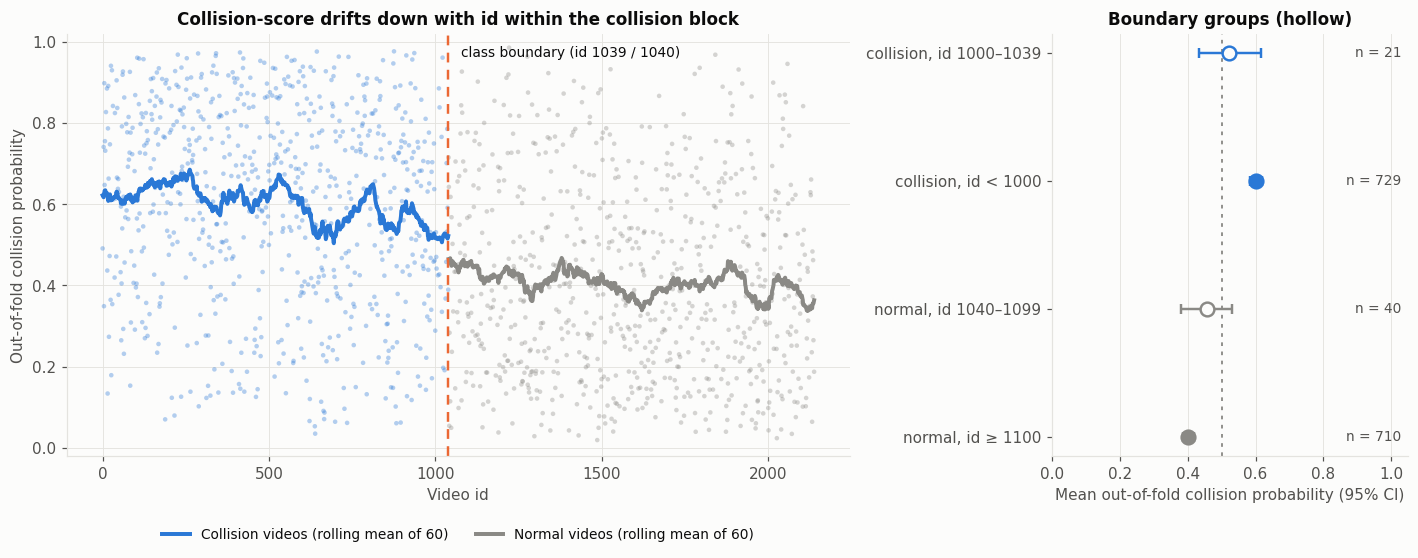

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
for target, colour, label in [(1, BLUE, "Collision videos"), (0, NEUTRAL, "Normal videos")]:
    s_ = meta[meta["target"] == target].sort_values("id")
    ax.scatter(s_["id"], s_["oof_p"], s=9, color=colour, alpha=0.35, edgecolors="none")
    ax.plot(s_["id"], s_["oof_p"].rolling(60, center=True, min_periods=30).mean(), color=colour, linewidth=2.6,
            label=f"{label} (rolling mean of 60)")
ax.axvline(1039.5, color=ORANGE, linewidth=1.6, linestyle=(0, (4, 3)))
ax.annotate("class boundary (id 1039 / 1040)", (1039.5, 0.99), xytext=(8, 0), textcoords="offset points", va="top", fontsize=9, color=INK)
ax.set_xlabel("Video id")
ax.set_ylabel("Out-of-fold collision probability")
ax.set_ylim(-0.02, 1.02)
ax.set_title("Collision-score drifts down with id within the collision block")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=9)

ax = axes[1]
labels = ["collision, id 1000–1039", "collision, id < 1000", "normal, id 1040–1099", "normal, id ≥ 1100"]
ys = np.arange(4)[::-1]
for y, (key, g), colour in zip(ys, groups.items(), [BLUE, BLUE, NEUTRAL, NEUTRAL]):
    m = g["oof_p"].mean()
    bs = [rng.choice(g["oof_p"].to_numpy(), len(g)).mean() for _ in range(2000)]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    hollow = "id 1000" in key or "id 1040" in key
    ax.errorbar(m, y, xerr=[[m - lo], [hi - m]], fmt="o", markersize=9, color=colour, markerfacecolor=SURFACE if hollow else colour,
                markeredgewidth=1.6, capsize=3, elinewidth=1.6)
    ax.text(1.03, y, f"n = {len(g)}", va="center", ha="right", fontsize=9, color=INK_2)
ax.set_yticks(ys)
ax.set_yticklabels(labels)
ax.set_xlim(0, 1.05)
ax.axvline(0.5, color=NEUTRAL, linestyle=(0, (2, 3)), linewidth=1.2)
ax.set_xlabel("Mean out-of-fold collision probability (95% CI)")
ax.grid(axis="y", visible=False)
ax.set_title("Boundary groups (hollow)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "id_block_fig1_scores_by_id.png", dpi=170)
plt.show()

## 7. Reading the results

Numbers from the run above (out-of-fold, all 1,500 videos, TTE = 1.0 s; collision-vs-normal out-of-fold AUC 0.72).

| Test | Result | Reads as |
|---|---|---|
| A. Within-class lower/upper id half | collision AUC 0.563 (shuffled-label 95th percentile 0.522); normal AUC 0.501 (null 0.54) | Weak id-ordered structure in the collision class; none detectable in the normal class |
| B. Boundary groups | boundary collisions score lower (−0.078, CI −0.17 to +0.02, p = 0.10); boundary normals score higher (+0.055, CI −0.02 to +0.13, p = 0.15) | Both shifts are toward the neighbouring class, but neither is significant (n = 21 and 40) |
| C. Within-class trend | collision: Spearman −0.128, permutation p = 0.0005 (mean score 0.64 in the lowest-id quartile to 0.57 in the highest); normal: −0.058, p = 0.10 | The collision score drifts down with id inside the collision block |
| D. Separation near the boundary | collision-vs-normal AUC 0.594 within ±100 ids of the boundary vs 0.730 farther away (difference −0.136, 95% CI −0.236 to −0.036); ±200 and ±300 windows agree | Class separation **shrinks where the classes are neighbours in id** |

**Interpretation.** These results are consistent with the features carrying some information about *where a video sits in the id ordering*, in addition to collision
content: the score decreases smoothly with id, and the classes become harder to separate precisely where their ids are close. A feature set that encoded collision
content only would not be expected to show test D. The effect is moderate and not the whole story: collision and normal videos are still separable far from the boundary
(AUC 0.73), and the within-class drift (about 0.07 in mean score) is small compared with the class gap (about 0.2).

**What this does not show.** It does not identify *what* changes with id (device, region, season, time of day, collection date, annotation batch), and an id-ordered effect
that is constant within each class would pass every test here. Ids could also be ordered by something genuinely related to the event (for example severity). The tests are
therefore evidence that the confound is plausible, not that it is proven or what causes it.

**Consequence for the report.** Treat the id-block structure as a real limitation: state that the learned model may partly be recognising recording/collection structure, and
word claims as "separates the two video groups" rather than "predicts imminent collisions". The raw-video comparison (`tools/compare_id_blocks.py`, to be run where the
dataset is available) is still needed to find out what differs between the blocks.